# 05 — Filtro de transições (modelo v1.1)

O notebook 04 mostrou que a maior parte dos alertas cai em **fronteiras de regime**:
leituras de 15 minutos que cobrem uma troca de estado (por exemplo, o desligamento dos
capacitores às 22h ou o início da pausa às 12h) e por isso misturam dois estados.

Este notebook avalia suprimir esses alertas e publica o resultado como **v1.1** do
modelo. Nada é reajustado: regimes, Isolation Forest e limiar continuam os da v1.0.

## Regra de decisão

- **Limiar mantido.** O filtro não muda o que é "incomum"; só deixa de alarmar quando a
  leitura incomum é explicada por uma troca de regime. Recalibrar para manter 1% de
  alertas encheria a lista de leituras pouco incomuns.
- **Ativar o filtro se**, na validação, a proporção de alertas em fronteira for pelo menos
  **3×** a proporção de leituras em fronteira (os alertas se concentram nas transições
  muito além do acaso).
- A alternativa (recalibrar o limiar só com leituras fora de fronteira) é reportada como
  sensibilidade.

## Ressalvas

- **A regra não é cega.** Ela foi escrita depois de o notebook 04 mostrar que 88% dos
  alertas da validação (90% no teste) caem em fronteira; documenta a decisão, não a testa.
- **Independência do teste.** O notebook 04 olhou o ano todo, teste incluído, antes desta
  mudança; os números da v1.1 no teste não são uma avaliação independente do filtro.
- **Atraso em tempo real.** Saber se uma leitura é fronteira exige a leitura seguinte:
  em operação contínua, o alerta sai com 15 minutos de atraso.
- **Ponto cego.** Uma falha que coincida exatamente com uma troca de regime deixa de
  alarmar. O escore continua disponível em `anomaly_score` e o sinal sem filtro em
  `is_anomaly_raw`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Raiz do projeto não encontrada.")


ROOT = find_root(Path.cwd())
sys.path.insert(0, str(ROOT / "src"))

from regime_anomaly import preprocessing as pp
from regime_anomaly.artifacts import write_manifest
from regime_anomaly.config import IMAGES_DIR, METADATA_DIR, MODELS_DIR, PROCESSED_DIR, TABLES_DIR
from regime_anomaly.data import DEFAULT_DATASET, load_data

HIGH_CONTRAST_PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
sns.set_theme(style="whitegrid", palette=HIGH_CONTRAST_PALETTE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)
MIN_LIFT = 3.0
PROFILE = [*pp.ENERGY_COLUMNS, *pp.POWER_FACTOR_COLUMNS]


def save_table(frame: pd.DataFrame, name: str, index: bool = True) -> None:
    frame.to_csv(TABLES_DIR / name, index=index, encoding="utf-8-sig")


bundle = joblib.load(MODELS_DIR / "final_model.joblib")
# Avalia sempre a partir do comportamento v1.0, mesmo se a v1.1 já estiver publicada.
print(f"Versão publicada ao abrir: {bundle.metadata.get('versao', '1.0')}")
bundle.transition_filter = False
prepared, _ = pp.prepare_frame(load_data())
predicted = bundle.predict(prepared)
predicted["intervalo"] = (
    (predicted[pp.TIMESTAMP_COLUMN] - pp.EXPECTED_FREQUENCY).dt.strftime("%H:%M")
    + "–"
    + predicted[pp.TIMESTAMP_COLUMN].dt.strftime("%H:%M")
)
print(f"Limiar v1.0: {bundle.anomaly_threshold:.4f}")

# load_data() mantém os nomes originais da UCI; o protocolo trabalha em snake_case.
LABEL_COLUMN = pp.LABEL


Versão publicada ao abrir: 1.0


Limiar v1.0: 0.6247


## 1. Validação

In [2]:
def filter_summary(frame: pd.DataFrame) -> dict[str, float]:
    raw = frame["is_anomaly_raw"]
    boundary = frame["regime_boundary"]
    kept = raw & ~boundary
    return {
        "leituras": len(frame),
        "leituras_em_fronteira": boundary.mean(),
        "alertas_sem_filtro": int(raw.sum()),
        "alertas_em_fronteira": raw[boundary].sum() / max(raw.sum(), 1),
        "lift_fronteira": (raw[boundary].sum() / max(raw.sum(), 1)) / boundary.mean(),
        "alertas_com_filtro": int(kept.sum()),
        "taxa_sem_filtro": raw.mean(),
        "taxa_com_filtro": kept.mean(),
    }


by_split = pd.DataFrame(
    {name: filter_summary(predicted[predicted[pp.SPLIT_COLUMN] == name]) for name in pp.SPLIT_NAMES}
).T
save_table(by_split, "filtro_transicao_resumo.csv")
display(by_split)

validation_lift = by_split.loc["validation", "lift_fronteira"]
ENABLE_FILTER = bool(validation_lift >= MIN_LIFT)
print(
    f"Lift na validação: {validation_lift:.1f}× (mínimo {MIN_LIFT:.0f}×) -> filtro {'ATIVADO' if ENABLE_FILTER else 'NÃO ativado'}"
)

,leituras,leituras_em_fronteira,alertas_sem_filtro,alertas_em_fronteira,lift_fronteira,alertas_com_filtro,taxa_sem_filtro,taxa_com_filtro
train,23328.000,0.119,471.000,0.796,6.715,96.000,0.020,0.004
validation,5856.000,0.093,59.000,0.881,9.505,7.000,0.010,0.001
test,5856.000,0.098,49.000,0.898,9.161,5.000,0.008,0.001


Lift na validação: 9.5× (mínimo 3×) -> filtro ATIVADO


In [3]:
validation = predicted[predicted[pp.SPLIT_COLUMN] == "validation"]
kept_validation = validation[validation["is_anomaly_raw"] & ~validation["regime_boundary"]]
print(f"Alertas mantidos na validação: {len(kept_validation)}")
display(
    kept_validation.sort_values("anomaly_score", ascending=False)[
        [pp.TIMESTAMP_COLUMN, pp.DAY_OF_WEEK, "intervalo", "regime_name", *PROFILE, "anomaly_score"]
    ]
)

Alertas mantidos na validação: 7


,timestamp,day_of_week,intervalo,regime_name,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
24132,2018-09-09 09:15:00,Sunday,09:00–09:15,ocioso capacitivo,10.220,0.110,5.470,99.990,88.170,0.649
24133,2018-09-09 09:30:00,Sunday,09:15–09:30,ocioso capacitivo,10.980,0.000,5.760,100.000,88.550,0.639
24134,2018-09-09 09:45:00,Sunday,09:30–09:45,ocioso capacitivo,11.450,0.000,5.400,100.000,90.450,0.635
24135,2018-09-09 10:00:00,Sunday,09:45–10:00,ocioso capacitivo,10.580,0.000,5.040,100.000,90.280,0.632
24136,2018-09-09 10:15:00,Sunday,10:00–10:15,ocioso capacitivo,11.090,0.000,5.040,100.000,91.040,0.628
28193,2018-10-21 16:30:00,Sunday,16:15–16:30,ocioso capacitivo,20.410,0.650,4.460,99.950,97.690,0.626
26737,2018-10-06 12:30:00,Saturday,12:15–12:30,produção,24.120,0.790,1.940,99.950,99.680,0.625


### Sensibilidade: recalibrar o limiar fora das fronteiras

Alternativa rejeitada pela regra: escolher um novo limiar para que 1% das leituras **fora
de fronteira** da validação vire alerta. A tabela mostra quantos alertas isso geraria e
quanto eles se repetem no mesmo dia da semana e intervalo (sinal de rotina, não de
evento).

In [4]:
non_boundary_val = validation[~validation["regime_boundary"]]
recalibrated_threshold = float(np.quantile(non_boundary_val["anomaly_score"], 0.99))
recalibrated = non_boundary_val[non_boundary_val["anomaly_score"] >= recalibrated_threshold]
weeks = recalibrated[pp.TIMESTAMP_COLUMN].dt.isocalendar().week
recurrence = (
    recalibrated.assign(semana=weeks)
    .groupby([pp.DAY_OF_WEEK, "intervalo"])["semana"]
    .transform("nunique")
)
sensitivity = pd.DataFrame(
    [
        {
            "opcao": "limiar v1.0 + filtro (escolhida)",
            "limiar": bundle.anomaly_threshold,
            "alertas_validacao": len(kept_validation),
            "recorrentes_3+_semanas": np.nan,
        },
        {
            "opcao": "limiar recalibrado fora de fronteira",
            "limiar": recalibrated_threshold,
            "alertas_validacao": len(recalibrated),
            "recorrentes_3+_semanas": float((recurrence >= 3).mean()),
        },
    ]
).set_index("opcao")
save_table(sensitivity, "filtro_transicao_sensibilidade.csv")
display(sensitivity)

,limiar,alertas_validacao,recorrentes_3+_semanas
opcao,,,
limiar v1.0 + filtro (escolhida),0.625,7,NaN
limiar recalibrado fora de fronteira,0.596,54,0.000


## 2. Os episódios suspeitos continuam sinalizados?

O notebook 04 apontou dois episódios no treino que merecem investigação (madrugadas de
15 a 23 de julho e manhã de 22 de maio). O filtro não pode apagá-los.

In [5]:
episodes = {
    "madrugadas 15–23/jul": (pd.Timestamp("2018-07-15"), pd.Timestamp("2018-07-24")),
    "manhã 22/mai": (pd.Timestamp("2018-05-22 08:00"), pd.Timestamp("2018-05-22 11:00")),
}
rows = []
for name, (start, end) in episodes.items():
    window = predicted[
        (predicted[pp.TIMESTAMP_COLUMN] > start) & (predicted[pp.TIMESTAMP_COLUMN] <= end)
    ]
    if name.startswith("madrugadas"):
        window = window[window[pp.TIMESTAMP_COLUMN].dt.hour < 6]
    rows.append(
        {
            "episodio": name,
            "alertas_sem_filtro": int(window["is_anomaly_raw"].sum()),
            "alertas_com_filtro": int(
                (window["is_anomaly_raw"] & ~window["regime_boundary"]).sum()
            ),
        }
    )
episode_check = pd.DataFrame(rows).set_index("episodio")
display(episode_check)

,alertas_sem_filtro,alertas_com_filtro
episodio,,
madrugadas 15–23/jul,29,22
manhã 22/mai,7,5


## 3. Teste (com ressalva de independência)

In [6]:
test = predicted[predicted[pp.SPLIT_COLUMN] == "test"]
kept_test = test[test["is_anomaly_raw"] & ~test["regime_boundary"]]
print(
    f"Teste: {int(test['is_anomaly_raw'].sum())} alertas sem filtro -> {len(kept_test)} com filtro"
)
display(
    kept_test.sort_values("anomaly_score", ascending=False)[
        [pp.TIMESTAMP_COLUMN, pp.DAY_OF_WEEK, "intervalo", "regime_name", *PROFILE, "anomaly_score"]
    ]
)

Teste: 49 alertas sem filtro -> 5 com filtro


,timestamp,day_of_week,intervalo,regime_name,usage_kwh,lagging_current_reactive_power_kvarh,leading_current_reactive_power_kvarh,lagging_current_power_factor,leading_current_power_factor,anomaly_score
32775,2018-12-08 10:00:00,Saturday,09:45–10:00,ocioso capacitivo,31.430,0.180,4.430,100.000,99.020,0.629
32103,2018-12-01 10:00:00,Saturday,09:45–10:00,ocioso capacitivo,28.580,0.040,5.830,100.000,97.980,0.629
32776,2018-12-08 10:15:00,Saturday,10:00–10:15,ocioso capacitivo,31.570,0.220,4.180,100.000,99.130,0.628
32104,2018-12-01 10:15:00,Saturday,10:00–10:15,ocioso capacitivo,28.730,0.000,5.940,100.000,97.930,0.625
32105,2018-12-01 10:30:00,Saturday,10:15–10:30,ocioso capacitivo,29.560,0.000,5.110,100.000,98.540,0.625


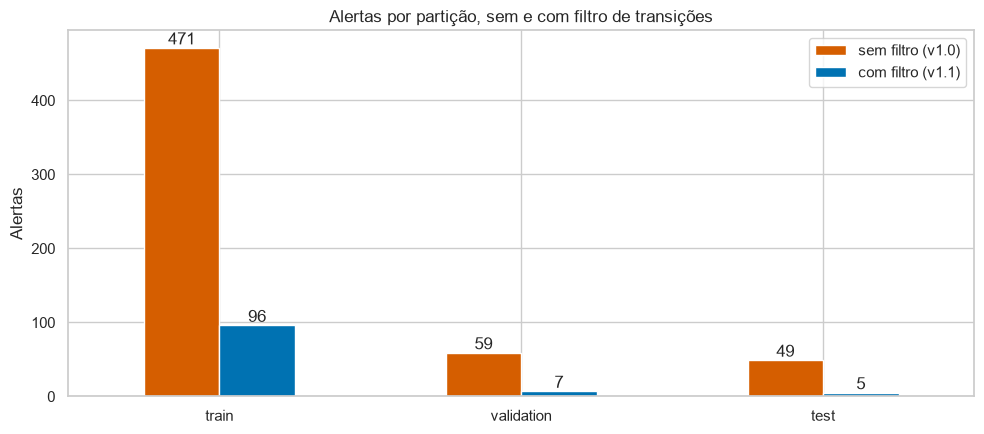

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = by_split[["alertas_sem_filtro", "alertas_com_filtro"]].reindex(pp.SPLIT_NAMES)
plot.plot.bar(ax=ax, color=[HIGH_CONTRAST_PALETTE[3], HIGH_CONTRAST_PALETTE[0]], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
ax.set(title="Alertas por partição, sem e com filtro de transições", xlabel="", ylabel="Alertas")
ax.legend(["sem filtro (v1.0)", "com filtro (v1.1)"])
fig.tight_layout()
fig.savefig(IMAGES_DIR / "32_filtro_transicao.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Publicação da v1.1

Se a regra ativou o filtro, o modelo é republicado com `transition_filter=True`.
`analysis_results.csv` passa a ter `is_anomaly` filtrado, mantendo `is_anomaly_raw` e
`regime_boundary`. `final_metrics.json` ganha o bloco `filtro_transicao`; as métricas do
protocolo original ficam inalteradas.

In [8]:
if ENABLE_FILTER:
    bundle.transition_filter = True
    bundle.metadata = {
        **bundle.metadata,
        "versao": "1.1",
        "mudancas": ["filtro de alertas em fronteira de regime (notebook 05)"],
    }
    joblib.dump(bundle, MODELS_DIR / "final_model.joblib")

    reloaded = joblib.load(MODELS_DIR / "final_model.joblib")
    results = reloaded.predict(prepared)
    assert reloaded.transition_filter
    assert not (results["is_anomaly"] & results["regime_boundary"]).any()

    columns = [
        pp.TIMESTAMP_COLUMN,
        pp.SPLIT_COLUMN,
        *pp.ELECTRICAL_COLUMNS,
        pp.NSM,
        pp.WEEK_STATUS,
        pp.DAY_OF_WEEK,
        LABEL_COLUMN,
        "regime",
        "regime_name",
        "regime_confidence",
        "anomaly_score",
        "is_anomaly_raw",
        "regime_boundary",
        "is_anomaly",
    ]
    columns = [column for column in columns if column in results.columns]
    results[columns].to_csv(PROCESSED_DIR / "analysis_results.csv", index=False, encoding="utf-8")

    metrics_path = METADATA_DIR / "final_metrics.json"
    final_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    final_metrics["filtro_transicao"] = {
        "versao_modelo": "1.1",
        "ativo": True,
        "regra": f"lift de alertas em fronteira >= {MIN_LIFT:.0f}x na validação",
        "lift_validacao": float(validation_lift),
        "limiar": bundle.anomaly_threshold,
        "por_particao": by_split[
            ["alertas_sem_filtro", "alertas_com_filtro", "taxa_sem_filtro", "taxa_com_filtro"]
        ].to_dict(orient="index"),
        "ressalva_teste": "recorrência analisada no ano todo; teste não totalmente independente",
    }
    metrics_path.write_text(
        json.dumps(final_metrics, ensure_ascii=False, indent=2, default=float), encoding="utf-8"
    )
    manifest = write_manifest(DEFAULT_DATASET)
    print(f"v1.1 publicada; manifesto com {len(manifest['artefatos'])} artefatos.")
else:
    print("Filtro não ativado; v1.0 permanece publicada.")

v1.1 publicada; manifesto com 44 artefatos.


## 5. Conclusões

- **Filtro ativado pela regra:** na validação, 88% dos alertas caem em fronteira de
  regime, contra 9% das leituras (lift de 9,5×).
- **Volume:** 59 → 7 alertas na validação e 49 → 5 no teste (de ~1% para ~0,1% das
  leituras), sem mudar o limiar.
- **O que sobra quase sempre tem uma assinatura comum:** 10 dos 12 alertas são carga
  média (10–31 kWh) com corrente adiantada em manhãs de fim de semana (09/09, 01/12 e
  08/12) — o mesmo perfil do episódio de 22/05. Os outros dois também são fim de semana
  com carga média: sábado 06/10 às 12:30 e domingo 21/10 às 16:30. Compatível com operação parcial com a compensação de reativos
  ligada; é o tipo de evento que vale levar à operação.
- **Custo do filtro:** no episódio das madrugadas de julho, 7 de 29 alertas caem porque o
  próprio evento gera trocas de regime; 22 continuam sinalizados, então o episódio segue
  visível. Uma falha que coincida exatamente com uma transição não alarma — por isso
  `is_anomaly_raw` e `anomaly_score` continuam publicados.
- **Alternativa rejeitada:** recalibrar o limiar fora das fronteiras geraria 54 alertas na
  validação, nenhum recorrente, mas a maioria pouco incomum — volume alto sem ganho claro.

**Pendente com a operação:** confirmar, na triagem do notebook 04, que transições não são
de interesse. Se forem, basta republicar com `transition_filter=False`.